<a href="https://colab.research.google.com/github/Jaygupta2502/120-Python-Projects/blob/main/SMARTWASTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PS 6: Smart Waste Segregation Classifier [Model Making]**

In [1]:
!pip -q install tensorflow scikit-learn seaborn

In [3]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_files = [f for f in uploaded if f.lower().endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the waste dataset as a ZIP file.")

ZIP_PATH = zip_files[0]
EXTRACT_PATH = "/content/waste_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")
print("Location:", EXTRACT_PATH)

train_dir = None
test_dir = None

for root, dirs, _ in os.walk(EXTRACT_PATH):
    folder_names = {d.upper(): d for d in dirs}

    if "TRAIN" in folder_names and "TEST" in folder_names:
        train_dir = os.path.join(root, folder_names["TRAIN"])
        test_dir = os.path.join(root, folder_names["TEST"])
        break

if train_dir is None:
    raise FileNotFoundError(
        "TRAIN and TEST folders not found. "
        "Check the ZIP structure of your dataset."
    )

print("Training folder:", train_dir)
print("Testing folder:", test_dir)
print("Training categories:", os.listdir(train_dir))

Saving archive.zip to archive.zip
Dataset extracted successfully!
Location: /content/waste_dataset
Training folder: /content/waste_dataset/DATASET/TRAIN
Testing folder: /content/waste_dataset/DATASET/TEST
Training categories: ['O', 'N', 'R']


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 15

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
class_names = sorted([
    name for name in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, name))
])

print("Detected classes:", class_names)

if len(class_names) != 3:
    print("WARNING: Expected 3 categories. Check your dataset.")

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

val_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names
)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="int",
    class_names=class_names
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

FRIENDLY_NAMES = {
    "O": "Biodegradable / Organic",
    "R": "Recyclable",
    "N": "Non-biodegradable / Residual",
    "organic": "Biodegradable / Organic",
    "recyclable": "Recyclable",
    "nonrecyclable": "Non-biodegradable / Residual",
    "non-recyclable": "Non-biodegradable / Residual"
}

display_names = [
    FRIENDLY_NAMES.get(c.lower(), c.title())
    for c in class_names
]

print("Model output classes:", display_names)

Detected classes: ['N', 'O', 'R']
Found 22564 files belonging to 3 classes.
Using 18052 files for training.
Found 22564 files belonging to 3 classes.
Using 4512 files for validation.
Found 2907 files belonging to 3 classes.
Model output classes: ['N', 'O', 'R']


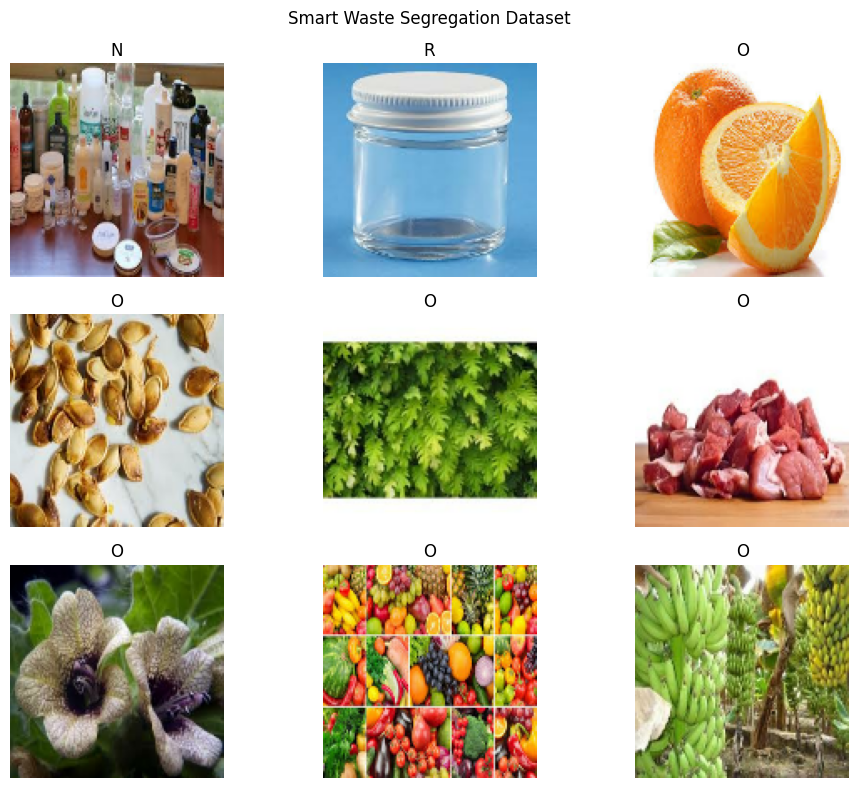

In [6]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(display_names[int(labels[i])])
        plt.axis("off")

plt.suptitle("Smart Waste Segregation Dataset")
plt.tight_layout()
plt.show()

In [7]:
model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1.0 / 255),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "/content/best_waste_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.7070 - loss: 0.7259 - val_accuracy: 0.6935 - val_loss: 0.7554 - learning_rate: 0.0010
Epoch 2/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step - accuracy: 0.7322 - loss: 0.6721 - val_accuracy: 0.7407 - val_loss: 0.6446 - learning_rate: 0.0010
Epoch 3/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.7385 - loss: 0.6447 - val_accuracy: 0.7518 - val_loss: 0.6186 - learning_rate: 0.0010
Epoch 4/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.7486 - loss: 0.6241 - val_accuracy: 0.7445 - val_loss: 0.6277 - learning_rate: 0.0010
Epoch 5/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 14s 26ms/step - accuracy: 0.7569 - loss: 0.6069 - val_accuracy: 0.7473 - val_loss: 0.6333 - learning_rate: 0.0010
Epoch 6/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 21s 27ms/step - accuracy: 0.7684 - loss: 0.5836 - val_accuracy: 0.7547 - val_loss: 0.6114 - learning_rate: 5.0000e-04
Epoch 7/15
565/565 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.7728

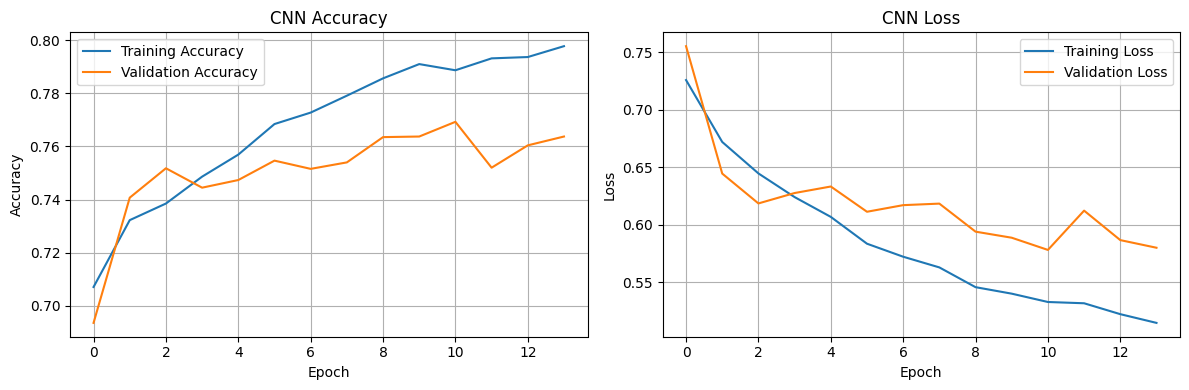

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7042 - loss: 0.6667
Test Loss: 0.6667
Test Accuracy: 70.42%


In [11]:
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Classification Report:\n")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=display_names,
    zero_division=0
))

91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step
Classification Report:

              precision    recall  f1-score   support

           N       0.27      0.26      0.26       394
           O       0.86      0.89      0.88      1401
           R       0.64      0.62      0.63      1112

    accuracy                           0.70      2907
   macro avg       0.59      0.59      0.59      2907
weighted avg       0.70      0.70      0.70      2907



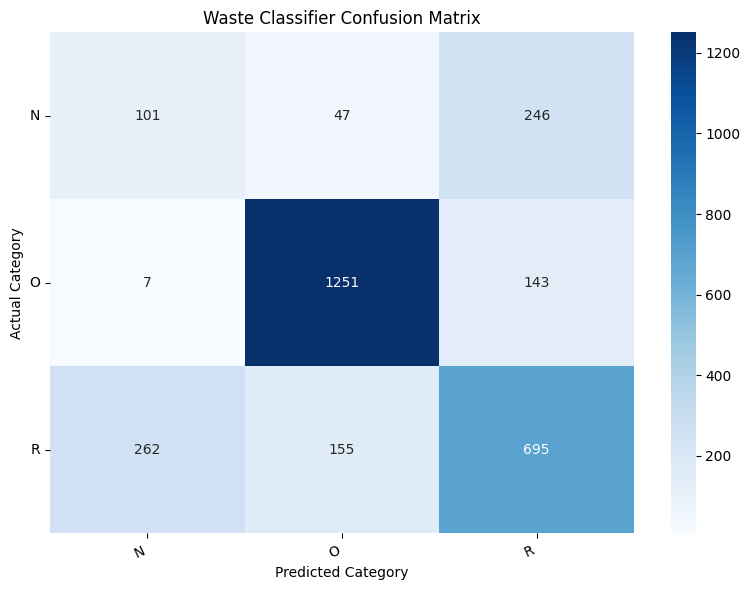

In [12]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=display_names,
    yticklabels=display_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Waste Classifier Confusion Matrix")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Saving 360_F_326303901_ryRXsWItNcIDvxnQ84HCTK8nuyvENH85.webp to 360_F_326303901_ryRXsWItNcIDvxnQ84HCTK8nuyvENH85 (1).webp


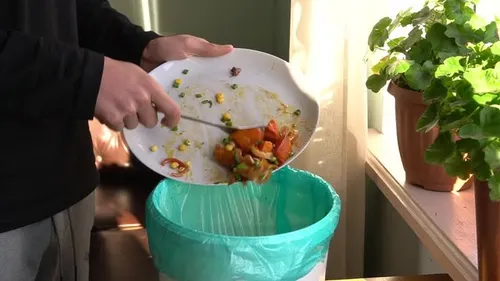


========== SMART WASTE CLASSIFIER ==========
Predicted category: Biodegradable / Organic Waste
Confidence: 69.72%

Category probabilities:
Non-biodegradable / Residual Waste: 16.22%
Biodegradable / Organic Waste: 69.72%
Recyclable Waste: 14.06%

Prediction available for demonstration.


In [15]:
from google.colab import files
from PIL import Image
from IPython.display import display
import numpy as np

# Human-readable names for dataset labels
label_names = {
    "O": "Biodegradable / Organic Waste",
    "N": "Non-biodegradable / Residual Waste",
    "R": "Recyclable Waste"
}

uploaded_photos = files.upload()

for filename in uploaded_photos:
    image = Image.open(filename).convert("RGB")
    display(image)

    img = image.resize(IMAGE_SIZE)
    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    probabilities = model.predict(img_array, verbose=0)[0]
    best_index = np.argmax(probabilities)

    label = class_names[best_index]
    confidence = float(probabilities[best_index])

    print("\n========== SMART WASTE CLASSIFIER ==========")
    print("Predicted category:", label_names.get(label, label))
    print(f"Confidence: {confidence * 100:.2f}%")

    print("\nCategory probabilities:")
    for name, prob in zip(class_names, probabilities):
        print(f"{label_names.get(name, name)}: {prob * 100:.2f}%")

    if confidence < 0.60:
        print("\nWARNING: Low confidence. Manual sorting recommended.")
    else:
        print("\nPrediction available for demonstration.")

    print("============================================")

In [14]:
MODEL_PATH = "/content/smart_waste_classifier.keras"

model.save(MODEL_PATH)

print("Model saved:", MODEL_PATH)

files.download(MODEL_PATH)

Model saved: /content/smart_waste_classifier.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
!pip -q install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 88.4 MB/s eta 0:00:00


Saving trash-bin-with-medical-pills-waste-of-different-packages-of-medicines-top-view-photo.webp to trash-bin-with-medical-pills-waste-of-different-packages-of-medicines-top-view-photo.webp


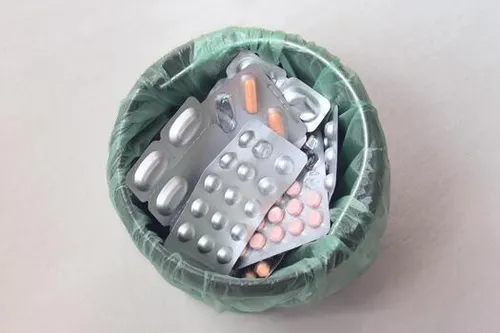


SMART WASTE SEGREGATION RESULT
Image: trash-bin-with-medical-pills-waste-of-different-packages-of-medicines-top-view-photo.webp
Waste type: R
Prediction confidence: 63.96%

All class probabilities:
N: 31.47%
O: 4.57%
R: 63.96%

Status: Prediction available - verify before physical sorting

PDF report generated: /content/Waste_Report_trash-bin-with-medical-pills-waste-of-different-packages-of-medicines-top-view-photo.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

from google.colab import files
from IPython.display import display, HTML
from PIL import Image
from datetime import datetime
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image as PDFImage, Table,
    TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import inch
import numpy as np
import os

WASTE_NAMES = {
    "O": "Biodegradable / Organic Waste",
    "N": "Non-biodegradable / Residual Waste",
    "R": "Recyclable Waste",
    "organic": "Biodegradable / Organic Waste",
    "recyclable": "Recyclable Waste",
    "non-recyclable": "Non-biodegradable / Residual Waste",
    "nonrecyclable": "Non-biodegradable / Residual Waste"
}

def readable_label(label):
    return WASTE_NAMES.get(label.lower(), label.title())

uploaded = files.upload()

for filename, _ in uploaded.items():
    if not filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".webp", ".bmp")
    ):
        print("Unsupported image format:", filename)
        continue

    try:
        original_image = Image.open(filename).convert("RGB")
        display(original_image)

        resized_image = original_image.resize(IMAGE_SIZE)
        img_array = np.asarray(resized_image, dtype=np.float32)
        img_array = np.expand_dims(img_array, axis=0)

        probabilities = model.predict(img_array, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))
        predicted_label = class_names[predicted_index]
        waste_type = readable_label(predicted_label)
        confidence = float(probabilities[predicted_index]) * 100

        print("\n" + "=" * 45)
        print("SMART WASTE SEGREGATION RESULT")
        print("=" * 45)
        print("Image:", filename)
        print("Waste type:", waste_type)
        print(f"Prediction confidence: {confidence:.2f}%")

        print("\nAll class probabilities:")
        for label, probability in zip(class_names, probabilities):
            print(
                f"{readable_label(label)}: "
                f"{probability * 100:.2f}%"
            )

        if confidence < 60:
            status = "LOW CONFIDENCE - Manual verification recommended"
        else:
            status = "Prediction available - verify before physical sorting"

        print("\nStatus:", status)

        image_path = "/content/waste_uploaded_image.jpg"
        original_image.save(image_path, format="JPEG", quality=90)

        timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        safe_name = os.path.splitext(os.path.basename(filename))[0]
        safe_name = "".join(
            c if c.isalnum() or c in "-_" else "_"
            for c in safe_name
        )
        pdf_path = f"/content/Waste_Report_{safe_name}.pdf"

        styles = getSampleStyleSheet()
        styles.add(ParagraphStyle(
            name="WasteTitle",
            parent=styles["Title"],
            alignment=TA_CENTER,
            textColor=colors.HexColor("#176B50"),
            fontSize=20,
            leading=25
        ))

        doc = SimpleDocTemplate(
            pdf_path,
            pagesize=A4,
            rightMargin=45,
            leftMargin=45,
            topMargin=40,
            bottomMargin=40
        )

        story = []
        story.append(Paragraph(
            "SMART WASTE SEGREGATION REPORT",
            styles["WasteTitle"]
        ))
        story.append(Spacer(1, 18))

        story.append(Paragraph(
            "Automated waste image classification result",
            styles["Heading2"]
        ))
        story.append(Spacer(1, 10))

        story.append(Paragraph("Uploaded Waste Image", styles["Heading2"]))
        story.append(PDFImage(
            image_path, width=3.5 * inch, height=3.0 * inch,
            kind="proportional"
        ))
        story.append(Spacer(1, 15))

        table_data = [
            ["Field", "Result"],
            ["Image filename", os.path.basename(filename)],
            ["Date and time", timestamp],
            ["Predicted waste type", waste_type],
            ["Model confidence", f"{confidence:.2f}%"],
            ["Prediction status", status]
        ]

        result_table = Table(
            table_data,
            colWidths=[150, 330],
            repeatRows=1
        )
        result_table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0),
             colors.HexColor("#176B50")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("VALIGN", (0, 0), (-1, -1), "TOP"),
            ("PADDING", (0, 0), (-1, -1), 8),
            ("BACKGROUND", (0, 1), (-1, -1),
             colors.HexColor("#F4F8F5"))
        ]))
        story.append(result_table)
        story.append(Spacer(1, 18))

        story.append(Paragraph(
            "Category Probability Breakdown",
            styles["Heading2"]
        ))

        probability_rows = [["Waste category", "Probability"]]
        for label, probability in zip(class_names, probabilities):
            probability_rows.append([
                readable_label(label),
                f"{probability * 100:.2f}%"
            ])

        probability_table = Table(
            probability_rows,
            colWidths=[300, 150],
            repeatRows=1
        )
        probability_table.setStyle(TableStyle([
            ("BACKGROUND", (0, 0), (-1, 0),
             colors.HexColor("#176B50")),
            ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
            ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
            ("PADDING", (0, 0), (-1, -1), 7)
        ]))
        story.append(probability_table)
        story.append(Spacer(1, 18))

        story.append(Paragraph(
            "<b>Important:</b> Confidence represents the model's "
            "predicted probability, not guaranteed correctness. "
            "Image classification alone cannot confirm material "
            "composition or local recycling eligibility. Verify "
            "the result before automatically sorting physical waste.",
            styles["BodyText"]
        ))

        doc.build(story)

        print("\nPDF report generated:", pdf_path)

        files.download(pdf_path)

    except Exception as e:
        print(f"Error processing {filename}: {e}")


In [18]:
from google.colab import files
files.download("/content/Smart_Waste_Segregation_Report.pdf")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>